<a href="https://colab.research.google.com/github/ZIZOUTOUMOU/LAB02-AdvDB/blob/main/georgia_covid_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
from google.colab import files
uploaded = files.upload()  # choose us-counties-2022.csv

Saving us-counties-2022.csv to us-counties-2022.csv


In [5]:
# ============================================================
# COVID-19 Visualisation Critique & Redesign  (Georgia, USA)
# Data: us-counties-2022.csv  (county-level cumulative cases, Jan-Dec 2022)
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

sns.set_theme(style="whitegrid")


In [6]:
# ---------- 1. LOAD & PREPARE ----------
# In Google Colab: run  `from google.colab import files; files.upload()`
# then choose us-counties-2022.csv (or mount Drive and change the path).
CSV_PATH = "us-counties-2022.csv"  # uploaded via the cell above
df = pd.read_csv(CSV_PATH, parse_dates=["date"])

# Keep Georgia only, then add up all counties for each date
ga = df[df["state"] == "Georgia"]
daily = ga.groupby("date", as_index=True)["cases"].sum().to_frame("cumulative_cases")

# The file holds CUMULATIVE cases, so daily new cases = day-to-day difference.
# clip(lower=0) removes tiny negative values caused by data corrections.
daily["new_cases"] = daily["cumulative_cases"].diff().clip(lower=0)

# 7-day rolling average (computed on the full year BEFORE filtering,
# so the first days of May are not distorted by the cut-off)
daily["rolling_7d"] = daily["new_cases"].rolling(7).mean()

# Focus period: May 2022 (same month as the original 2020 DPH chart)
may = daily.loc["2022-05-01":"2022-05-31"].copy()
print(may[["new_cases", "rolling_7d"]].describe().round(0))


       new_cases  rolling_7d
count       31.0        31.0
mean      1285.0      1360.0
std       3481.0       405.0
min          0.0       816.0
25%          0.0       934.0
50%          0.0      1262.0
75%         68.0      1523.0
max      13645.0      1965.0


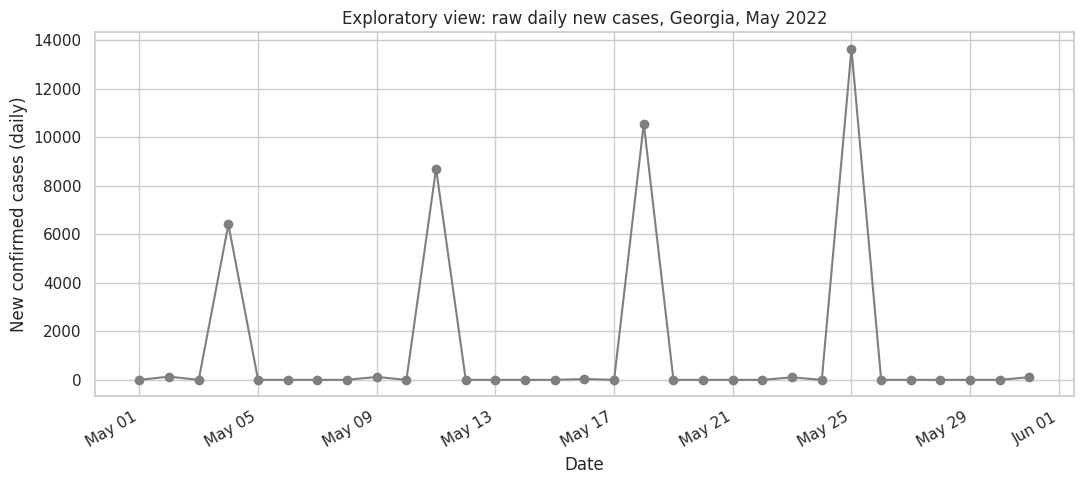

In [7]:
# ---------- 2. EXPLORATORY PLOT (raw, unsmoothed) ----------
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(may.index, may["new_cases"], marker="o", color="tab:gray")
ax.set_title("Exploratory view: raw daily new cases, Georgia, May 2022")
ax.set_xlabel("Date")
ax.set_ylabel("New confirmed cases (daily)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("1_exploratory.png", dpi=150)
plt.show()
# Observation: Georgia reported in weekly batches in 2022, so most days are 0
# with one big spike per week. The raw series is noisy and hard to read.


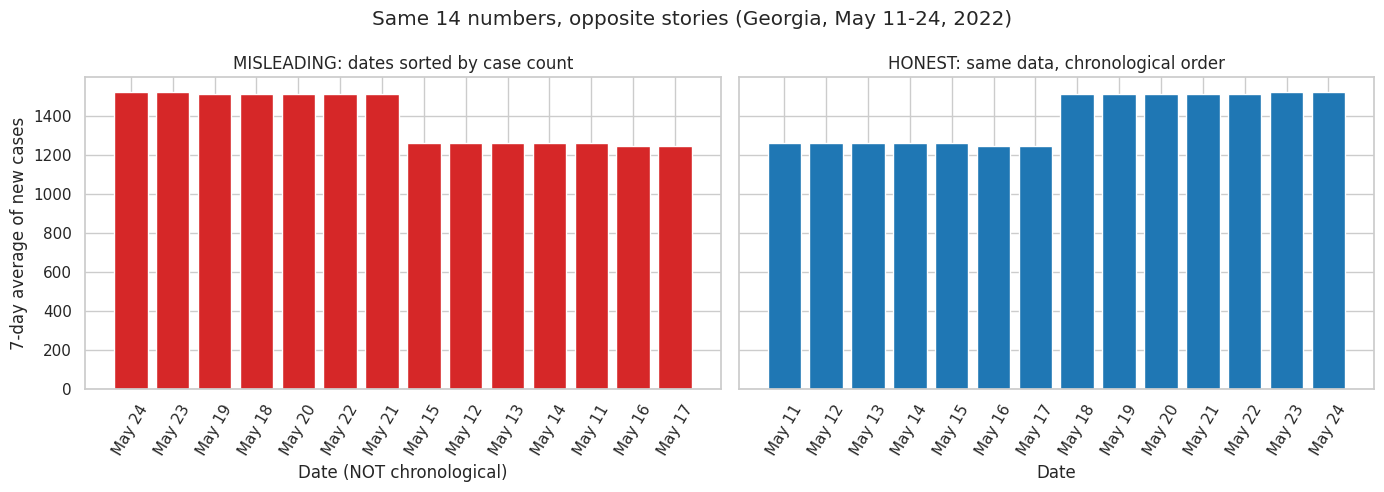

In [8]:
# ---------- 3. MISLEADING RECREATION (educational use only!) ----------
# Take a 14-day segment and sort by value, highest first - the trick used
# in the Georgia DPH chart. We sort the 7-day average because the raw daily
# values are mostly zeros (weekly reporting).
segment = may.loc["2022-05-11":"2022-05-24", "rolling_7d"]
fake = segment.sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].bar(fake.index.strftime("%b %d"), fake.values, color="tab:red")
axes[0].set_title("MISLEADING: dates sorted by case count")
axes[0].set_xlabel("Date (NOT chronological)")
axes[0].set_ylabel("7-day average of new cases")
axes[0].tick_params(axis="x", rotation=60)

axes[1].bar(segment.index.strftime("%b %d"), segment.values, color="tab:blue")
axes[1].set_title("HONEST: same data, chronological order")
axes[1].set_xlabel("Date")
axes[1].tick_params(axis="x", rotation=60)

fig.suptitle("Same 14 numbers, opposite stories (Georgia, May 11-24, 2022)")
plt.tight_layout()
plt.savefig("2_misleading_vs_honest.png", dpi=150)
plt.show()


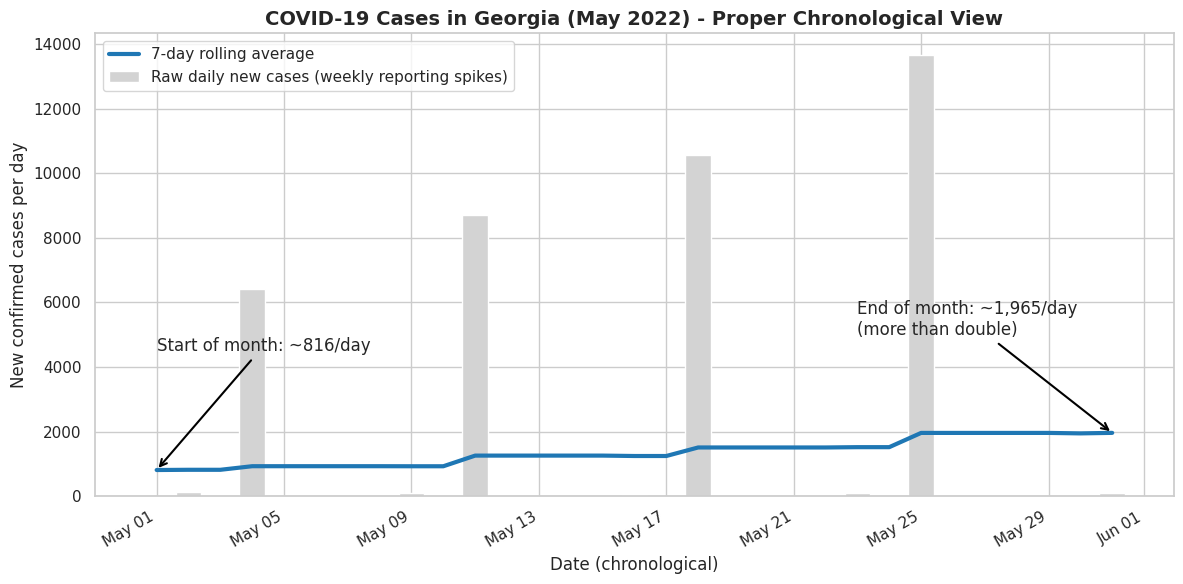

In [9]:
# ---------- 4. EXPLANATORY VISUALISATION ----------
fig, ax = plt.subplots(figsize=(12, 6))

# Raw data as light context (weekly batch spikes), smoothed trend on top
ax.bar(may.index, may["new_cases"], color="lightgray", width=0.8,
       label="Raw daily new cases (weekly reporting spikes)")
ax.plot(may.index, may["rolling_7d"], color="tab:blue", linewidth=3,
        label="7-day rolling average")

# Annotations built from the data itself
low_day = may["rolling_7d"].idxmin()
high_day = may["rolling_7d"].idxmax()
ax.annotate(f"Start of month: ~{may['rolling_7d'].iloc[0]:,.0f}/day",
            xy=(may.index[0], may["rolling_7d"].iloc[0]),
            xytext=(may.index[0], 4500), arrowprops=dict(arrowstyle="->", color="black", lw=1.5))
ax.annotate(f"End of month: ~{may['rolling_7d'].iloc[-1]:,.0f}/day\n(more than double)",
            xy=(may.index[-1], may["rolling_7d"].iloc[-1]),
            xytext=(may.index[-9], 5000), arrowprops=dict(arrowstyle="->", color="black", lw=1.5))
# EDIT THIS: add your own event, e.g. the date of the original DPH chart
# ax.axvline(pd.Timestamp("2022-05-11"), ls="--", color="k")

ax.set_title("COVID-19 Cases in Georgia (May 2022) - Proper Chronological View",
             fontsize=14, weight="bold")
ax.set_xlabel("Date (chronological)")
ax.set_ylabel("New confirmed cases per day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig("3_explanatory.png", dpi=150)
plt.show()


## Part 1 – Critique of the Georgia DPH chart (May 2020)
**What was done:** 14 days of new cases were plotted with the dates sorted from highest to lowest count instead of chronologically, producing a smooth 'decline'.

**Perception / clarity:** Readers assume a left-to-right x-axis is time. Breaking that convention makes a sorted list look like a trend.

**Context / purpose:** The implied message ('cases are falling') could support reopening, but the real daily data was fluctuating with no clear decline.

**Tufte:** *Graphical integrity* – the picture does not represent the data's true structure. *Clarity* – the axis order confuses rather than reveals. *Comparison over time* – impossible, since time order is destroyed.

## Part 2 – Commentary (edit with your own words)
In the recreation, the 14 values are identical in both panels. Only the ordering changes, yet the red chart shows a steady fall while the blue one shows a rise. The rolling average in the final plot shows Georgia's May 2022 trend honestly: ~816/day rising to ~1,965/day, with raw weekly spikes kept as grey context.